In [3]:
import sys 
sys.path.append('../src')

from data_processing.load import load_and_preprocess_data

from data_processing.utils import load_checkpoint, save_checkpoint, run_inference_bnn, run_svi
from models.model import quantile_gen_model, quantile_cf_model

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal
from numpyro.optim import Adam
import numpyro.distributions as dist



In [4]:
jax.config.update('jax_num_cpu_devices', 6) # I have 8 physical cores

### Load data and preprocess
- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:
- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)

In [5]:
from operator import itemgetter
data = load_and_preprocess_data()
(X_train, X_test, Y_train_gen, Y_test_gen,
 Y_train_cf, Y_test_cf, Y_train_aval, Y_test_aval,
 sites_meta, feature_cols) = itemgetter(
    "X_train","X_test","Y_train_gen","Y_test_gen",
    "Y_train_cf","Y_test_cf","Y_train_aval","Y_test_aval",
    "sites_meta","feature_cols"
)(data)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:60: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Quantile BNN
input 
- X: (timestamps, wind parks, features)
- Quantiles: (q)

output: (q, timestamps)


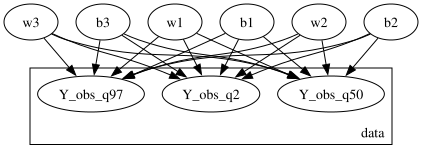

In [6]:
import numpyro
numpyro.render_model(
    quantile_gen_model,
    model_args=(X_test,),
)

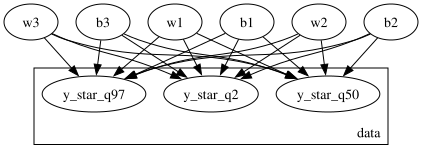

In [7]:
numpyro.render_model(
    quantile_cf_model,
    model_args=(X_test,),
)

In [8]:
# args = {
#     'num_warmup': 10,
#     'num_samples': 30,
#     'num_chains': 5,
# }
args = dict(
    num_warmup=50,
    num_samples=100,
    num_chains=1,
)

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC

In [12]:
samples_gen = run_inference_bnn(quantile_gen_model, args, rng_key, X_train, Y_train_gen)

sample: 100%|██████████| 150/150 [02:26<00:00,  1.02it/s, 255 steps of size 4.45e-03. acc. prob=0.11]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.84      0.04      0.84      0.81      0.88      9.31      1.27
     b1[1]      0.25      0.06      0.23      0.20      0.41      9.20      1.03
     b1[2]      9.06      0.15      9.01      8.96      9.37      7.66      1.13
     b1[3]     -4.41      0.16     -4.46     -4.53     -4.10      5.94      1.37
     b1[4]     -3.23      0.02     -3.23     -3.25     -3.20      6.24      1.35
     b1[5]      0.60      0.05      0.62      0.52      0.65      4.71      1.36
     b1[6]     -9.85      0.08     -9.85     -9.99     -9.74      3.82      1.71
     b1[7]     -2.90      0.04     -2.90     -2.95     -2.87     16.06      1.17
     b1[8]      3.10      0.14      3.03      2.95      3.33      3.09      2.25
     b1[9]     -0.63      0.10     -0.61     -0.82     -0.55      9.03      1.19
    b1[10]     -0.67      0.07     -0.66     -0.74     -0.63     15.40      1.06
    b1[11]      5.28      0

In [ ]:
save_checkpoint(samples_gen, "quantile_gen_model", args, rng_key)

Saved checkpoint for model 'quantile_gen_model': ../../checkpoints/quantile_gen_model_2025-11-03_11-04-09_gen.pkl


'../../checkpoints/quantile_gen_model_2025-11-03_11-04-09_gen.pkl'

In [9]:
state_ckp = load_checkpoint(file_name='quantile_gen_model_2025-11-03_11-04-09_gen')
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

Loading specified checkpoint: ../checkpoints/quantile_gen_model_2025-11-03_11-04-09_gen.pkl


In [10]:
preds_MCMC_gen = Predictive(quantile_gen_model, samples_ckp)(rng_key_predict_ckp, X_test)

In [25]:
samples_cf = run_inference_bnn(quantile_cf_model, args, rng_key, X_train, Y_train_cf)

warmup:  13%|█▎        | 19/150 [00:18<02:05,  1.04it/s, 31 steps of size 1.48e-03. acc. prob=0.65]


KeyboardInterrupt: 

In [26]:
state_ckp = load_checkpoint(file_name='quantile_cf_model_2025-11-03_12-42-25_gen')
samples_ckp = state_ckp['samples']
args_ckp = state_ckp['args']
rng_key_ckp = state_ckp['rng_key']
rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

Loading specified checkpoint: ../checkpoints/quantile_cf_model_2025-11-03_12-42-25_gen.pkl


In [28]:
preds_MCMC_cf_logit = Predictive(quantile_cf_model, samples_ckp)(rng_key_predict_ckp, X_test)
preds_MCMC_cf = {k: jax.nn.sigmoid(v) for k, v in preds_MCMC_cf_logit.items()}

In [71]:
save_checkpoint(samples_cf, "quantile_cf_model", args, rng_key)

Saved checkpoint for model 'quantile_cf_model': ../../checkpoints/quantile_cf_model_2025-11-03_12-42-25_gen.pkl


'../../checkpoints/quantile_cf_model_2025-11-03_12-42-25_gen.pkl'

Run VI

In [ ]:
guide = AutoNormal(quantile_cf_model)
svi_result = run_svi(quantile_cf_model, guide, rng_key, X_train, Y_train_cf, num_steps=1000)
params = svi_result.params
preds_VI_cf_logit = Predictive(quantile_cf_model, guide=guide, params=params, num_samples=500)(rng_key_predict, X_test)
preds_VI_cf = {k: jax.nn.sigmoid(v) for k, v in preds_VI_cf_logit.items()}

Final ELBO loss: 177126.609


### Evaluation

In [29]:
preds = preds_MCMC_cf
# CF: preds_VI and preds_MCMC_cf
# Gen: preds_MCMC

In [13]:
# Gen Model
q025 = preds['Y_obs_q2'].mean(axis=0)
q50 = preds['Y_obs_q50'].mean(axis=0)
q975 = preds['Y_obs_q97'].mean(axis=0)

In [30]:
# CF Model
q025 = preds['y_star_q2'].mean(axis=0)
q50 = preds['y_star_q50'].mean(axis=0)
q975 = preds['y_star_q97'].mean(axis=0)

In [14]:
rmse = jnp.sqrt(jnp.mean((q50  - Y_test_gen) ** 2)) # * Y_test_aval
print("Test RMSE (Median):", rmse)

Test RMSE (Median): 67.96151


In [31]:
rmse = jnp.sqrt(jnp.mean((q50 * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (Cf, Median):", rmse)

Test RMSE (Cf, Median): 74.65094


Empirical coverage of percentiles

In [15]:
inside = (Y_test_gen >= q025) & (Y_test_gen <= q975)
coverage_90 = inside.mean()
print(f"Empirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_gen <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.025–0.975): 0.458
Below median (should be ~0.5): 0.408


In [32]:
# TODO: fix intervals, wrong signs right now
inside = (Y_test_cf >= q025) & (Y_test_cf <= q975)
coverage_90 = inside.mean()
print(f"Empirical coverage cf (0.05–0.95): {coverage_90:.3f}")

below_median = (Y_test_cf <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Empirical coverage cf (0.05–0.95): 0.000
Below median (should be ~0.5): 0.546


### Plots

Variational Inference loss

Final ELBO loss: 177126.609


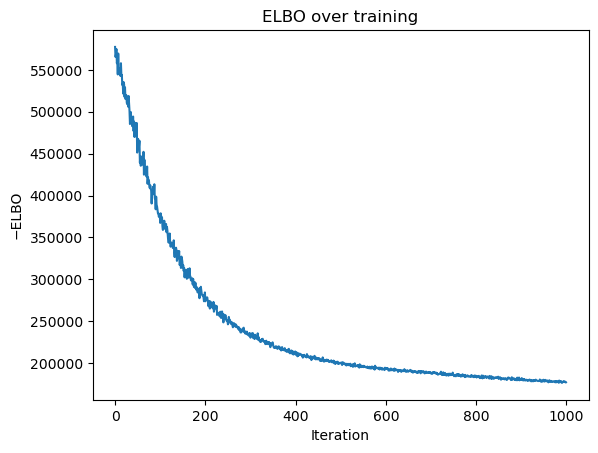

In [64]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()


Different intervals (percentile vs. hdi vs. normal)

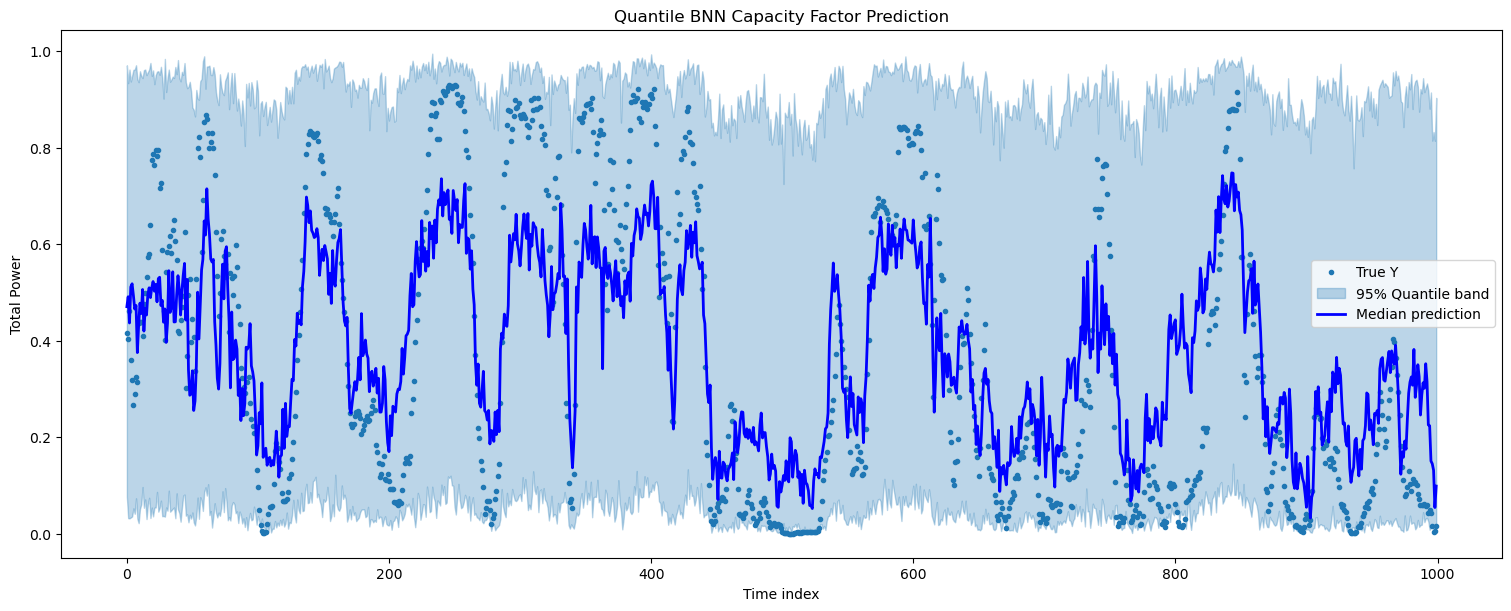

In [33]:
# Plot 90% CI
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_cf[:n_plot], ".", label="True Y")
ax.fill_between(X_new, q025[:n_plot], q975[:n_plot], color="C0", alpha=.3, label="95% Quantile band")
ax.plot(X_new, q50[:n_plot], "b", lw=2, label="Median prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="Quantile BNN Capacity Factor Prediction")
ax.legend()
plt.show()


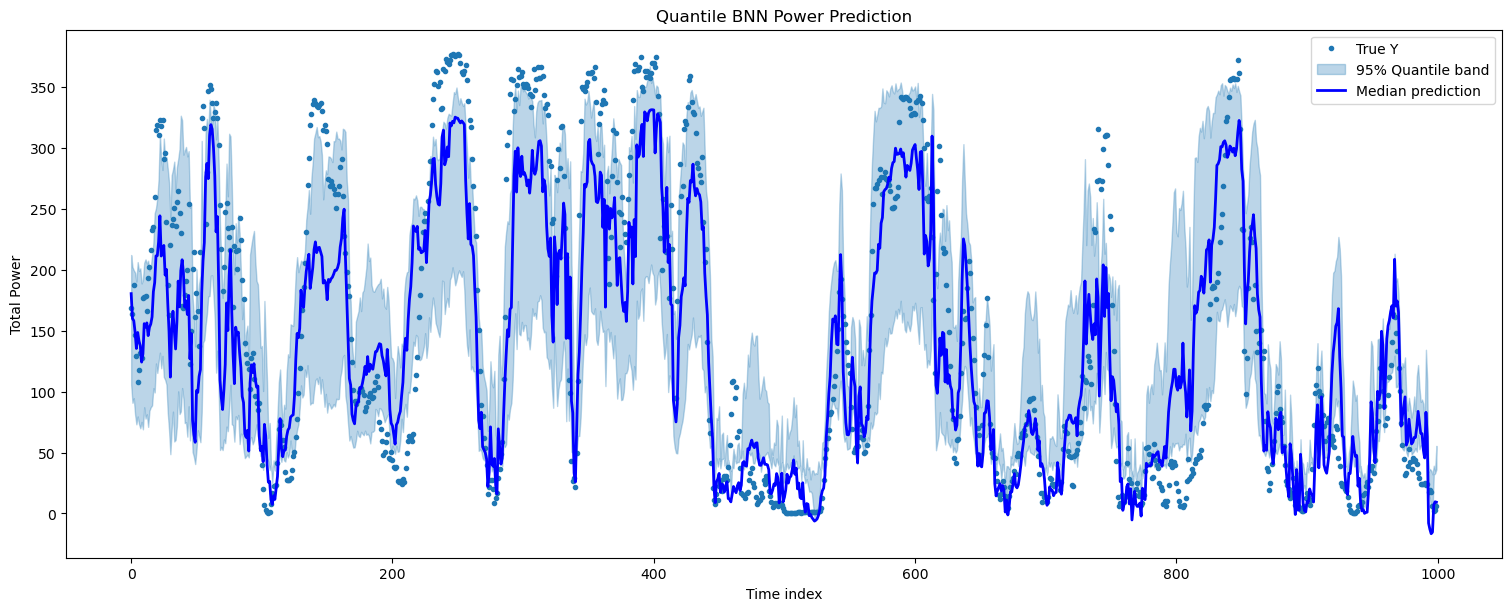

In [16]:
# Plot 95% CI
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_gen[:n_plot], ".", label="True Y")
ax.fill_between(X_new, q025[:n_plot], q975[:n_plot], color="C0", alpha=.3, label="95% Quantile band")
ax.plot(X_new, q50[:n_plot], "b", lw=2, label="Median prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="Quantile BNN Power Prediction")
ax.legend()
plt.show()


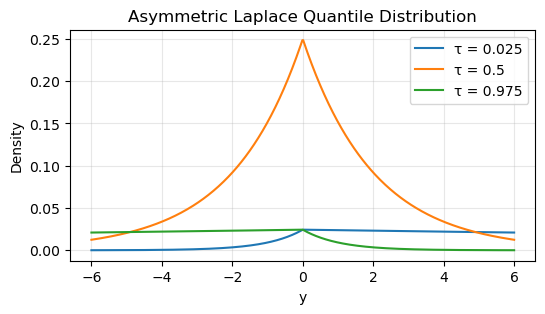

In [34]:
loc = 0.0
scale = 1.0
quantiles = [0.025, 0.5, 0.975]

x = jnp.linspace(-6, 6, 500)

plt.figure(figsize=(6,3))
for q in quantiles:
    d = dist.AsymmetricLaplaceQuantile(loc=loc, scale=scale, quantile=q)
    pdf = jnp.exp(d.log_prob(x))
    plt.plot(x, pdf, label=f"τ = {q}")

plt.title("Asymmetric Laplace Quantile Distribution")
plt.xlabel("y")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


PIT (Probability Integral Transform)
- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
    - Take all model’s predictive samples for that data point
    - Compute how many of those samples are less than or equal to the actual observed value
    - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
    - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$

PIT mean (of median): 0.6520345519049823 (should be uniform if calibrated)


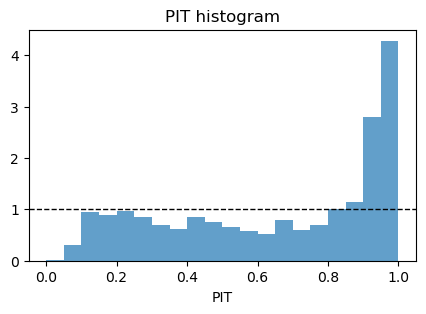

In [90]:
pits = np.array([percentileofscore(preds["Y_q0.50"][:, t], Y_test_gen[t], kind='mean') / 100.0 for t in range(preds["Y_q0.50"].shape[1])])
pits_mean = pits.mean()
print(f"PIT mean (of median): {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5,3))
plt.hist(pits, bins=20, range=(0,1), density=True, alpha=0.7)
plt.axhline(1.0, color='k', ls='--', lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()